# Inference on the test slide

What every method does on the held-out slides — never seen by pretraining, training or selection — read from what
`mxseg eval … --split test --unit region` stored: `results/region/test/<run>/` (`metrics.json`, `per_region.csv`) and the
predicted instance maps under `outputs/region/test/<run>/`. The test split holds two slides: **SLIDE-0236 (Slide 2)**, the
primary test slide — six expert-reviewed regions, 6,152 confirmed cells — and **SLIDE-0233 (Slide 3)**, four immune-rich
fields. `metrics.json` pools both; this notebook never uses that pooled number. Every score here is re-pooled from
`per_region.csv` for one slide (`TEST_SLIDE`, Slide 2): the tables, curves, maps, crops and taxonomy are Slide 2, and
Slide 3 gets its own compact table in section 1. Whole regions, predicted from 256 px tiles on the training grid and
stitched; flagged cells are neither ground truth nor false positives. Trained rows (ViT-B encoders, 10-epoch budget)
appear as `<method>_s<seed>` and are pooled over their three seeds (mean ± std); zero-shot rows have no seed. Works while
the job is still running: a method enters once its results exist.

| section | question |
|---|---|
| 1 | the tables: every stored metric on Slide 2, mean ± std over seeds; Slide 3 apart |
| 2 | scores at IoU 0.5, the whole IoU curve, and the precision–recall trade-off |
| 3 | per region: where each method is strong and weak |
| 4 | error anatomy: found, missed, invented; the error taxonomy (split, merged, missed, poor boundary, gained); AJI; the size of the cells that are missed |
| 5 | error maps of a whole region, one per method |
| 6 | where the errors are: the taxonomy painted on the same region |
| 7 | the same crops through every method |
| 8 | what convinces: consensus across methods and the label-noise ceiling, test–retest stability over seeds, and whether the models separate what HALO merged |
| 9 | where the misses come from: crowding and tissue compartment; paired per-region differences with confidence intervals |

In [1]:
import json, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle

from mxdata import DEFAULT_DATASET, apply_qc_policy, ingest, load_config, load_regions
from mxdata.data import LiveSource
from mxdata.data.composite import render_channels
from mxdata.pipeline.stats import NormStats
from mxseg.evaluate import SUMMARY_KEYS
from mxseg.metrics import aggregate, instance_outcomes, relabel

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, PRED = REPO / "results" / "region" / "test", REPO / "outputs" / "region" / "test"
DATASET = Path(DEFAULT_DATASET)

# ---- edit here ---------------------------------------------------------------------------------------------------------
TEST_SLIDE = "SLIDE-0236"              # the primary test slide (Slide 2): every number, map and crop below is this slide alone
SLIDE_NAME = {"SLIDE-0235": "Slide 1", "SLIDE-0236": "Slide 2", "SLIDE-0233": "Slide 3"}   # the paper's names
SEED = 0                               # the seed drawn in sections 4-7 (tables and curves pool every seed)
REGION_MAP = None                      # the region of the whole-region maps (sections 5-6): a key like "SLIDE-0236_R03", or None = the hardest
SHOW = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "cellpose_ft", "cellpose", "sam3"]   # crop columns, in order (those evaluated)
CROPS = [("SLIDE-0236_R02", 200, 300), ("SLIDE-0236_R04", 500, 900), ("SLIDE-0236_R06", 300, 100)]   # (region, y, x) of 384² crops
CROP = 384
# ------------------------------------------------------------------------------------------------------------------------

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
PAPER = ["unet_flows", "kodiakb_flows", "dinov3b_flows", "kodiakb_frozen", "dinov3b_frozen", "cellpose_ft",
         "cellpose", "cpdino", "instanseg", "sam3", "sam3_text", "sam2"]              # the paper's rows, trained then zero-shot
LABEL = {"unet_flows": "U-Net", "kodiakb_flows": "KODIAK B/16", "dinov3b_flows": "DINOv3 B/16",
         "kodiakb_frozen": "KODIAK B/16, frozen", "dinov3b_frozen": "DINOv3 B/16, frozen", "cellpose_ft": "Cellpose, adapted",
         "cellpose": "Cellpose-SAM, zero-shot", "cpdino": "Cellpose (DINOv3), zero-shot", "instanseg": "InstanSeg",
         "sam3": "SAM 3, exemplar", "sam3_text": "SAM 3, text", "sam2": "SAM 2.1, prototype",
         "kodiak_flows": "KODIAK S/16", "dinov3_flows": "DINOv3 S/16", "kodiak_frozen": "KODIAK S/16, frozen", "dinov3_frozen": "DINOv3 S/16, frozen"}   # ViT-S rows: tolerated if ever stored
MCOLOR = {"unet_flows": "#2A78D6", "kodiakb_flows": "#7E1F2E", "dinov3b_flows": "#6E5314", "kodiakb_frozen": "#DF959E",
          "dinov3b_frozen": "#D3BF8C", "cellpose_ft": "#EB6834", "cellpose": "#8A8A8A", "cpdino": "#5A5A5A", "instanseg": "#3C9D9B",
          "sam3": "#1BAF7A", "sam3_text": "#E87BA4", "sam2": "#9A86E0",
          "kodiak_flows": "#C43E4E", "dinov3_flows": "#B08A2E", "kodiak_frozen": "#DF959E", "dinov3_frozen": "#D3BF8C"}
VERDICT = {"tp": "#1BAF7A", "fn": "#8E5BE0", "fp": "#E34948", "wrong": "#EDA100"}
TAXO = {"correct": "#1BAF7A", "boundary": "#F2C230", "split": "#FF7F0E", "merged": "#1E90FF", "missed": "#8E5BE0", "gained": "#E34948"}
TAXO_LABEL = {"correct": "correct (IoU ≥ 0.5)", "boundary": "poor boundary (one prediction, IoU < 0.5)", "split": "split (≥ 2 predictions)",
              "merged": "merged (one prediction, ≥ 2 cells)", "missed": "missed (no prediction)", "gained": "gained (prediction on nothing)"}
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.0, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def hexrgb(h):
    return np.array([int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)])

def lab(m):
    return LABEL.get(m, m)

SEED_RE = re.compile(r"^(.*)_s(\d+)$")
def slide_of(key):
    return key.rsplit("_R", 1)[0]                                                  # "SLIDE-0236_R03" -> "SLIDE-0236"
runs = []                                                                          # every stored run of the test split
for m in sorted(RESULTS.glob("*/metrics.json")):
    name = m.parent.name
    mm = SEED_RE.match(name)
    method, seed = (mm.group(1), int(mm.group(2))) if mm else (name, None)
    per_all = pd.read_csv(m.parent / "per_region.csv"); per_all["slide"] = per_all.key.map(slide_of)
    # mxseg eval pooled every slide of the split into metrics.json; re-pool the per-region counts one slide at a time instead
    by_slide = {s: aggregate(g.to_dict("records")) for s, g in per_all.groupby("slide")}
    if TEST_SLIDE not in by_slide:
        continue
    runs.append({"run": name, "method": method, "seed": seed, "metrics": by_slide[TEST_SLIDE],
                 "per_region": per_all[per_all.slide == TEST_SLIDE].reset_index(drop=True), "by_slide": by_slide, "per_all": per_all})
if not runs:
    raise FileNotFoundError(f"no results for {TEST_SLIDE} under {RESULTS} — scripts/finetune_all.sh evaluates every run on the test split")
OTHER_SLIDES = sorted({s for r in runs for s in r["by_slide"]} - {TEST_SLIDE})     # the other test slide(s), reported apart
METHODS = [m for m in PAPER if any(r["method"] == m for r in runs)] + sorted({r["method"] for r in runs} - set(PAPER))
BY = {m: [r for r in runs if r["method"] == m] for m in METHODS}
THR = sorted({float(k.split("@")[1]) for k in runs[0]["metrics"] if re.match(r"f1@\d", k)})
def stat(m, key):
    v = np.array([r["metrics"][key] for r in BY[m] if key in r["metrics"]], float)
    return (v.mean(), v.std(ddof=0), len(v)) if len(v) else (np.nan, np.nan, 0)
def load_prediction(path):
    """A stored instance map (outputs/region/test/<run>/<region>.npz, written by mxseg eval)."""
    return np.load(path)["pred"].astype(np.int32)

def rep_run(m):
    """The run drawn in the crops: the chosen seed, else the first available."""
    for r in BY[m]:
        if r["seed"] == SEED:
            return r
    return BY[m][0]
n_gt = runs[0]["metrics"].get("n_gt")
print(f"{len(runs)} run(s), {len(METHODS)} method(s): " + ", ".join(f"{lab(m)} (n = {len(BY[m])})" for m in METHODS))
print(f"{TEST_SLIDE} ({SLIDE_NAME.get(TEST_SLIDE, 'test')}, the primary test slide): {runs[0]['metrics']['n_patches']} regions, {n_gt:,} scored cells")
for s in OTHER_SLIDES:
    print(f"also stored, reported apart and never pooled with it: {s} ({SLIDE_NAME.get(s, s)}): "
          f"{runs[0]['by_slide'][s]['n_patches']} fields, {runs[0]['by_slide'][s]['n_gt']:,} scored cells")

24 run(s), 12 method(s): U-Net (n = 3), KODIAK B/16 (n = 3), DINOv3 B/16 (n = 3), KODIAK B/16, frozen (n = 3), DINOv3 B/16, frozen (n = 3), Cellpose, adapted (n = 3), Cellpose-SAM, zero-shot (n = 1), Cellpose (DINOv3), zero-shot (n = 1), InstanSeg (n = 1), SAM 3, exemplar (n = 1), SAM 3, text (n = 1), SAM 2.1, prototype (n = 1)
SLIDE-0236 (Slide 2, the primary test slide): 6 regions, 6,152 scored cells
also stored, reported apart and never pooled with it: SLIDE-0233 (Slide 3): 4 fields, 2,329 scored cells


## 1. The tables

In [2]:
pd.set_option("display.width", 220)
def slide_table(slide, keys=SUMMARY_KEYS):
    """One row per method on one slide: mean ± std over seeds (population std) of every summary metric, re-pooled from that slide's regions only."""
    rows = []
    for m in METHODS:
        rs = [r for r in BY[m] if slide in r["by_slide"]]
        if not rs:
            continue
        row = {"method": lab(m), "seeds": len(rs), "n": rs[0]["by_slide"][slide]["n_patches"]}
        for k in keys:
            v = np.array([r["by_slide"][slide][k] for r in rs], float)
            row[k] = f"{v.mean():.3f} ± {v.std(ddof=0):.3f}" if len(v) > 1 else f"{v[0]:.3f}"
        row["s/region"] = round(float(np.mean([r["per_all"].loc[r["per_all"].slide == slide, "seconds"].mean() for r in rs])), 3)
        rows.append(row)
    return pd.DataFrame(rows)

table = slide_table(TEST_SLIDE)
print(f"Table 1 — {TEST_SLIDE} ({SLIDE_NAME.get(TEST_SLIDE, 'test')}, the primary test slide): {runs[0]['metrics']['n_patches']} regions, {n_gt:,} confirmed cells")
display(table.style.hide(axis="index").format({"s/region": "{:.2f}"}))
print("mean ± std over seeds (population std); n = regions of the slide | AP = TP / (TP + FP + FN); PQ = SQ × RQ; count ratio = predicted / true cells")
inst = pd.read_csv(DATASET / "instances.csv"); own = inst[(inst.slide == TEST_SLIDE) & inst.owned]
n_halo, n_wrong = len(own), int((own.flag == "WRONG").sum())
print(f"HALO itself (the commercial reference): {n_halo:,} cells, {n_wrong:,} flagged wrong by the expert -> precision {1 - n_wrong / n_halo:.3f}, "
      f"count ratio {n_halo / (n_halo - n_wrong):.2f} against the confirmed cells; its recall is unknowable (the review only strikes cells out)")
for s in OTHER_SLIDES:                                                             # the other test slide, the same way, on its own
    t = slide_table(s, ["f1@0.5", "ap@0.5", "ap@0.5:0.9", "pq@0.5", "precision@0.5", "recall@0.5", "count_ratio"])
    print(f"\nTable 2 — {s} ({SLIDE_NAME.get(s, s)}): {runs[0]['by_slide'][s]['n_patches']} fields, {runs[0]['by_slide'][s]['n_gt']:,} confirmed cells — "
          f"computed the same way, reported apart from {TEST_SLIDE}, never pooled with it")
    display(t.style.hide(axis="index").format({"s/region": "{:.2f}"}))


Table 1 — SLIDE-0236 (Slide 2, the primary test slide): 6 regions, 6,152 confirmed cells


method,seeds,n,f1@0.5,ap@0.5,ap@0.5:0.9,pq@0.5,precision@0.5,recall@0.5,mean_iou@0.5,count_ratio,dice,s/region
U-Net,3,6,0.875 ± 0.003,0.778 ± 0.005,0.480 ± 0.005,0.685 ± 0.004,0.915 ± 0.004,0.838 ± 0.003,0.783 ± 0.003,0.915 ± 0.003,0.864 ± 0.001,5.94
KODIAK B/16,3,6,0.877 ± 0.008,0.781 ± 0.012,0.504 ± 0.009,0.697 ± 0.007,0.929 ± 0.000,0.830 ± 0.014,0.795 ± 0.001,0.894 ± 0.015,0.865 ± 0.004,8.56
DINOv3 B/16,3,6,0.863 ± 0.010,0.759 ± 0.015,0.451 ± 0.017,0.665 ± 0.011,0.924 ± 0.004,0.809 ± 0.014,0.771 ± 0.006,0.875 ± 0.011,0.847 ± 0.004,8.90
"KODIAK B/16, frozen",3,6,0.814 ± 0.008,0.686 ± 0.011,0.392 ± 0.007,0.618 ± 0.006,0.910 ± 0.007,0.736 ± 0.008,0.759 ± 0.001,0.809 ± 0.003,0.809 ± 0.006,9.31
"DINOv3 B/16, frozen",3,6,0.840 ± 0.002,0.724 ± 0.003,0.424 ± 0.009,0.644 ± 0.005,0.919 ± 0.003,0.773 ± 0.004,0.767 ± 0.005,0.841 ± 0.007,0.832 ± 0.004,11.06
"Cellpose, adapted",3,6,0.901 ± 0.005,0.819 ± 0.008,0.551 ± 0.011,0.726 ± 0.007,0.923 ± 0.005,0.879 ± 0.008,0.806 ± 0.004,0.952 ± 0.010,0.882 ± 0.004,14.41
"Cellpose-SAM, zero-shot",1,6,0.781,0.641,0.292,0.550,0.701,0.883,0.704,1.261,0.822,53.20
"Cellpose (DINOv3), zero-shot",1,6,0.781,0.641,0.276,0.541,0.717,0.858,0.693,1.197,0.812,17.70
InstanSeg,1,6,0.766,0.620,0.313,0.556,0.856,0.693,0.726,0.809,0.713,6.44
"SAM 3, exemplar",1,6,0.842,0.727,0.403,0.633,0.857,0.828,0.752,0.966,0.826,147.11


mean ± std over seeds (population std); n = regions of the slide | AP = TP / (TP + FP + FN); PQ = SQ × RQ; count ratio = predicted / true cells
HALO itself (the commercial reference): 7,662 cells, 1,510 flagged wrong by the expert -> precision 0.803, count ratio 1.25 against the confirmed cells; its recall is unknowable (the review only strikes cells out)

Table 2 — SLIDE-0233 (Slide 3): 4 fields, 2,329 confirmed cells — computed the same way, reported apart from SLIDE-0236, never pooled with it


method,seeds,n,f1@0.5,ap@0.5,ap@0.5:0.9,pq@0.5,precision@0.5,recall@0.5,count_ratio,s/region
U-Net,3,4,0.786 ± 0.002,0.647 ± 0.003,0.397 ± 0.008,0.612 ± 0.005,0.861 ± 0.003,0.723 ± 0.003,0.840 ± 0.005,3.77
KODIAK B/16,3,4,0.784 ± 0.007,0.645 ± 0.010,0.422 ± 0.009,0.623 ± 0.007,0.872 ± 0.002,0.712 ± 0.012,0.816 ± 0.013,4.49
DINOv3 B/16,3,4,0.765 ± 0.010,0.620 ± 0.013,0.372 ± 0.009,0.589 ± 0.008,0.863 ± 0.003,0.688 ± 0.016,0.797 ± 0.019,4.40
"KODIAK B/16, frozen",3,4,0.726 ± 0.009,0.570 ± 0.011,0.328 ± 0.005,0.551 ± 0.006,0.850 ± 0.008,0.633 ± 0.009,0.745 ± 0.005,4.82
"DINOv3 B/16, frozen",3,4,0.754 ± 0.002,0.605 ± 0.003,0.353 ± 0.009,0.575 ± 0.004,0.868 ± 0.005,0.667 ± 0.001,0.768 ± 0.004,6.08
"Cellpose, adapted",3,4,0.797 ± 0.003,0.662 ± 0.004,0.445 ± 0.008,0.640 ± 0.005,0.859 ± 0.005,0.743 ± 0.007,0.864 ± 0.012,5.25
"Cellpose-SAM, zero-shot",1,4,0.655,0.486,0.234,0.465,0.586,0.741,1.263,21.43
"Cellpose (DINOv3), zero-shot",1,4,0.662,0.494,0.230,0.465,0.604,0.732,1.213,6.59
InstanSeg,1,4,0.657,0.489,0.266,0.486,0.767,0.574,0.748,4.02
"SAM 3, exemplar",1,4,0.734,0.580,0.324,0.550,0.810,0.672,0.830,64.87


**Table 1 — Every stored metric on Slide 2 (SLIDE-0236), the primary test slide**, re-pooled from its six regions in
`per_region.csv` (`metrics.json` pools both test slides and is not used), mean ± std over the three seeds of each trained
method (zero-shot methods have one run). The paper's headline is F1 at IoU 0.5; AP 0.5:0.9 and PQ weigh boundary
quality; precision against recall says whether a method loses cells or invents them; count ratio says the same in one
number. **Table 2 — Slide 3 (SLIDE-0233)**, the four immune-rich fields of the third slide, computed the same way and
reported apart: the two slides are never pooled.

## 2. Scores, the IoU curve, and the trade-off

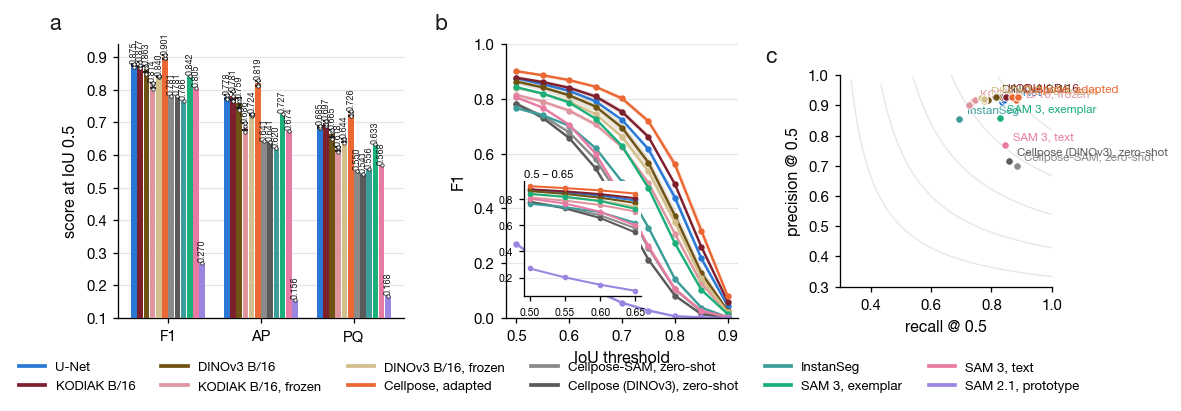

In [3]:
fig = plt.figure(figsize=(7.6, 2.9))
gs = fig.add_gridspec(1, 3, width_ratios=[1.35, 1.1, 1], wspace=0.42, left=0.08, right=0.99, top=0.9, bottom=0.2)
a = fig.add_subplot(gs[0])
keys = [("f1@0.5", "F1"), ("ap@0.5", "AP"), ("pq@0.5", "PQ")]
w = 0.8 / len(METHODS)
for i, m in enumerate(METHODS):
    for j, (k, _) in enumerate(keys):
        mu, sd, n = stat(m, k)
        a.bar(j + (i - len(METHODS) / 2 + 0.5) * w, mu, w * 0.92, color=MCOLOR.get(m, "#999"), zorder=3, yerr=sd if n > 1 else None,
              error_kw=dict(lw=0.8, capsize=1.5, ecolor=INK))
        for r in BY[m]:
            a.plot(j + (i - len(METHODS) / 2 + 0.5) * w, r["metrics"][k], "o", ms=1.8, color="white", mec=INK, mew=0.4, zorder=4)
vals = [stat(m, k)[0] for m in METHODS for k, _ in keys]
a.set_xticks(range(len(keys)), [t for _, t in keys]); a.set_ylabel("score at IoU 0.5"); a.set_ylim(np.floor((min(vals) - 0.04) * 20) / 20, min(1, max(vals) + 0.04)); ygrid(a)
for i, m in enumerate(METHODS):
    for j, (k, _) in enumerate(keys):
        a.text(j + (i - len(METHODS) / 2 + 0.5) * w, stat(m, k)[0] + stat(m, k)[1] + 0.004, f"{stat(m, k)[0]:.3f}", ha="center", va="bottom", fontsize=4.8, rotation=90, color=INK)
panel(a, "a", dx=-0.2)
b_ = fig.add_subplot(gs[1])
for m in METHODS:
    mu = np.array([stat(m, f"f1@{t:g}")[0] for t in THR]); sd = np.array([stat(m, f"f1@{t:g}")[1] for t in THR])
    b_.plot(THR, mu, "-o", ms=2.4, lw=1.3, color=MCOLOR.get(m, "#999"), label=lab(m))
    if len(BY[m]) > 1:
        b_.fill_between(THR, mu - sd, mu + sd, color=MCOLOR.get(m, "#999"), alpha=0.15, lw=0)
b_.set_xlabel("IoU threshold"); b_.set_ylabel("F1"); b_.set_ylim(0, 1); ygrid(b_)
ins = b_.inset_axes([0.08, 0.08, 0.5, 0.42])                                       # zoom on the detection end of the curve
for m in METHODS:
    mu = np.array([stat(m, f"f1@{t:g}")[0] for t in THR[:4]]); ins.plot(THR[:4], mu, "-o", ms=2, lw=1.1, color=MCOLOR.get(m, "#999"))
ins.set_xticks(THR[:4]); ins.tick_params(labelsize=5.5); ins.set_title("0.5 – 0.65", fontsize=6, pad=2); ins.grid(axis="y", color=GRID, lw=0.5)
panel(b_, "b", dx=-0.25)
c = fig.add_subplot(gs[2])
for m in METHODS:
    for r in BY[m]:
        c.plot(r["metrics"]["recall@0.5"], r["metrics"]["precision@0.5"], "o", ms=4, color=MCOLOR.get(m, "#999"), mec="white", mew=0.5, zorder=4)
    mu_r, mu_p = stat(m, "recall@0.5")[0], stat(m, "precision@0.5")[0]
    c.annotate(lab(m), (mu_r, mu_p), xytext=(4, 3), textcoords="offset points", fontsize=6.2, color=MCOLOR.get(m, "#999"))
lo = min(min(stat(m, "recall@0.5")[0], stat(m, "precision@0.5")[0]) for m in METHODS)
for f in np.arange(0.5, 1.0, 0.1):                                                 # iso-F1 curves
    rr = np.linspace(0.3, 1, 100); pp = f * rr / np.maximum(2 * rr - f, 1e-6)
    ok = (pp <= 1) & (pp >= 0.3); c.plot(rr[ok], pp[ok], color=GRID, lw=0.7, zorder=1)
c.set_xlim(max(0.3, np.floor((lo - 0.05) * 10) / 10), 1.0); c.set_ylim(max(0.3, np.floor((lo - 0.05) * 10) / 10), 1.0)
c.set_xlabel("recall @ 0.5"); c.set_ylabel("precision @ 0.5"); c.set_aspect("equal")
panel(c, "c", dx=-0.3)
fig.legend(handles=[plt.Line2D([], [], color=MCOLOR.get(m, "#999"), lw=2, label=lab(m)) for m in METHODS], ncol=min(6, len(METHODS)),
           loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=7)
plt.show()

**Figure 1 — Scores on Slide 2 (SLIDE-0236).** (a) F1, AP and PQ at IoU 0.5 per method, mean over seeds with the seeds as dots
and ± 1 std as the error bar — differences within a bar's error are not differences. (b) F1 as the IoU threshold tightens
from 0.5 to 0.9: the height at 0.5 is detection, the slope is boundary agreement with HALO's DAPI + LAP2 outlines, so two
curves that meet at 0.5 and part at 0.8 differ in shape, not in finding cells. (c) Precision against recall at 0.5, one
dot per run, gray lines are iso-F1: a method above the diagonal loses cells, one below invents them.

## 3. Per region

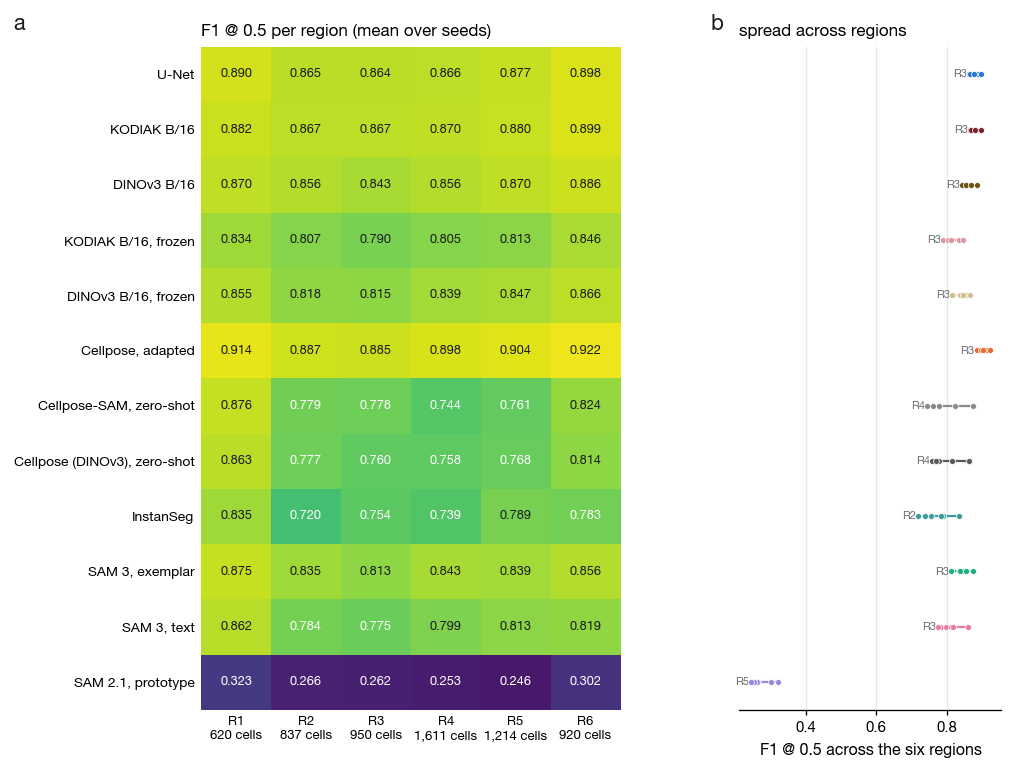

hardest region per method (lowest F1): U-Net: R3, KODIAK B/16: R3, DINOv3 B/16: R3, KODIAK B/16, frozen: R3, DINOv3 B/16, frozen: R3, Cellpose, adapted: R3, Cellpose-SAM, zero-shot: R4, Cellpose (DINOv3), zero-shot: R4, InstanSeg: R2, SAM 3, exemplar: R3, SAM 3, text: R3, SAM 2.1, prototype: R5


In [4]:
cfg = load_config(REPO / "configs" / "dataset.yaml")
paths, mx, _ = ingest(TEST_SLIDE, None)
regions = {r.key: r for r in load_regions(paths, None, cfg.min_area_px)}
KEYS = sorted(regions)
per = []
for m in METHODS:
    for r in BY[m]:
        p = r["per_region"].copy(); p["method"], p["seed"] = m, r["seed"]
        p["f1"] = 2 * p["tp@0.5"] / (2 * p["tp@0.5"] + p["fp@0.5"] + p["fn@0.5"]).clip(lower=1)
        p["precision"] = p["tp@0.5"] / (p["tp@0.5"] + p["fp@0.5"]).clip(lower=1); p["recall"] = p["tp@0.5"] / (p["tp@0.5"] + p["fn@0.5"]).clip(lower=1)
        p["scored"] = p["tp@0.5"] + p["fn@0.5"]
        per.append(p)
per = pd.concat(per)
mean = per.groupby(["method", "key"])[["f1", "precision", "recall", "scored"]].mean().reset_index()
M = mean.pivot(index="method", columns="key", values="f1").reindex(index=METHODS, columns=KEYS)
fig = plt.figure(figsize=(7.6, 0.42 * len(METHODS) + 2.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], wspace=0.35, left=0.2, right=0.98, top=0.86, bottom=0.2)
a = fig.add_subplot(gs[0])
im = a.imshow(M.values, cmap="viridis", vmin=max(0, np.nanmin(M.values) - 0.05), vmax=min(1, np.nanmax(M.values) + 0.02), aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        if np.isfinite(v):
            a.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=6.8, color="white" if v < np.nanmean(M.values) else INK)
n_scored = mean.groupby("key").scored.first().reindex(KEYS)
a.set_xticks(range(len(KEYS)), [f"R{regions[k].region_id}\n{int(n_scored[k]):,} cells" for k in KEYS], fontsize=7)
a.set_yticks(range(len(METHODS)), [lab(m) for m in METHODS], fontsize=7.4)
a.set_title("F1 @ 0.5 per region (mean over seeds)"); a.tick_params(length=0)
for s in a.spines.values(): s.set_visible(False)
panel(a, "a", dx=-0.42, dy=1.02)
b_ = fig.add_subplot(gs[1])
for i, m in enumerate(METHODS):
    row = M.loc[m]
    b_.plot(row.values, [i] * len(row), "o", ms=3.2, color=MCOLOR.get(m, "#999"), mec="white", mew=0.4, zorder=4)
    b_.plot([row.min(), row.max()], [i, i], lw=1.2, color=MCOLOR.get(m, "#999"), zorder=3)
    for k, v in row.items():
        if v == row.min():
            b_.text(v - 0.006, i, f"R{regions[k].region_id}", ha="right", va="center", fontsize=6, color=MUTED)
b_.set_yticks(range(len(METHODS)), [""] * len(METHODS)); b_.set_ylim(len(METHODS) - 0.5, -0.5); b_.invert_yaxis(); b_.set_ylim(len(METHODS) - 0.5, -0.5)
b_.set_xlabel("F1 @ 0.5 across the six regions"); xgrid(b_); b_.spines["left"].set_visible(False); b_.tick_params(axis="y", length=0)
b_.set_title("spread across regions")
panel(b_, "b", dx=-0.06, dy=1.02)
plt.show()
print("hardest region per method (lowest F1): " + ", ".join(f"{lab(m)}: R{regions[M.loc[m].idxmin()].region_id}" for m in METHODS))

**Figure 2 — Where each method is strong and weak.** (a) F1 at IoU 0.5 per region of Slide 2, averaged over seeds, with the
number of scored cells per region under its label: a column that is dark for every method is a hard region, a cell that
is dark in one row is a method's weakness. (b) The same numbers as a range per method, the hardest region named — a
short bar is a method that behaves the same everywhere, which matters more for downstream analysis than the mean.

## 4. Error anatomy

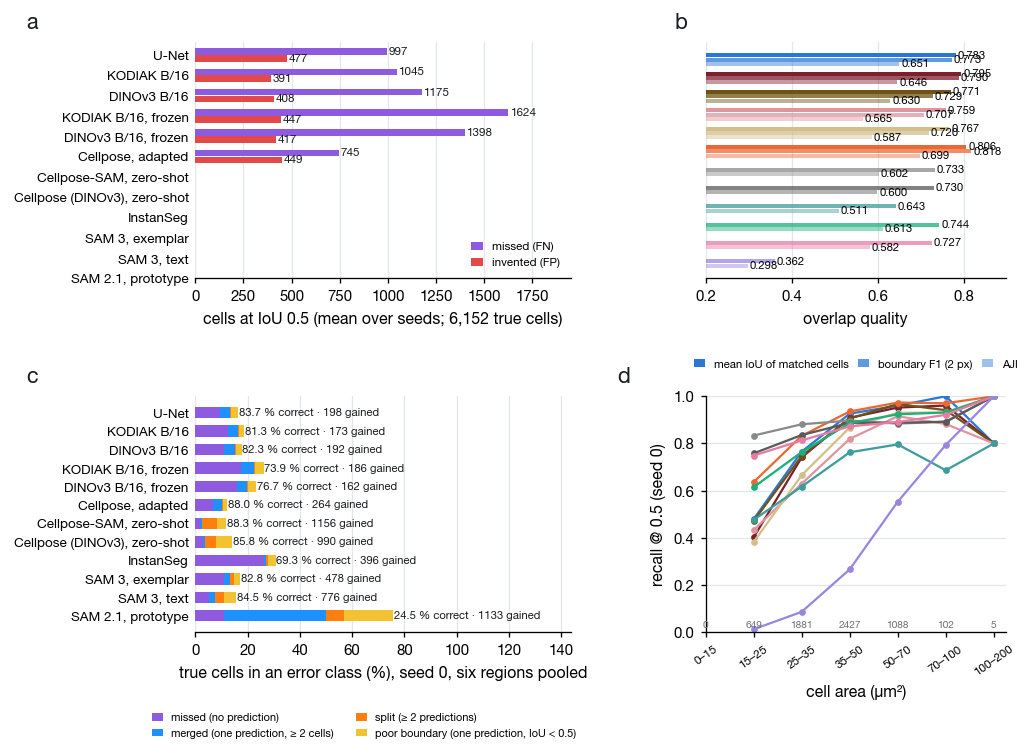

                                tp@0.5   fp@0.5    fn@0.5   miou    AJI  boundary_F1  correct %  boundary %  split %  merged %  missed %  gained
U-Net                         5155.000  476.667   997.000  0.783  0.651        0.773       83.7         2.5      0.6       3.8       9.3     198
KODIAK B/16                   5107.000  391.000  1045.000  0.795  0.646        0.790       81.3         2.1      0.5       3.8      12.4     173
DINOv3 B/16                   4976.667  407.667  1175.333  0.771  0.630        0.729       82.3         2.2      0.5       4.1      10.9     192
KODIAK B/16, frozen           4528.333  447.000  1623.667  0.759  0.565        0.707       73.9         3.1      0.5       5.0      17.5     186
DINOv3 B/16, frozen           4753.667  417.333  1398.333  0.767  0.587        0.720       76.7         3.1      0.4       4.0      15.8     162
Cellpose, adapted             5407.333  448.667   744.667  0.806  0.699        0.818       88.0         1.4      0.5       3.3    

In [5]:
from mxseg.metrics import iou_matrix

tot = per.groupby(["method", "seed"])[["tp@0.5", "fp@0.5", "fn@0.5", "iou_sum@0.5"]].sum().reset_index()
tot["miou"] = tot["iou_sum@0.5"] / tot["tp@0.5"].clip(lower=1)
agg = tot.groupby("method")[["tp@0.5", "fp@0.5", "fn@0.5", "miou"]].mean().reindex(METHODS)

src = LiveSource(mx, list(regions.values()), ["DAPI", "LAP2"], cfg.level)
GT = {}
for k in KEYS:
    rs = src.load(k)
    labels, ignore = apply_qc_policy(rs.labels, rs.flags, "ignore_wrong")
    GT[k] = (rs.image, labels, ignore)

def outcomes(m, k):
    """Verdicts at IoU 0.5 for one method (its chosen seed) on one region, plus what the taxonomy needs: the coverage matrices."""
    r = rep_run(m); path = PRED / r["run"] / f"{k}.npz"
    if not path.is_file():
        return None
    o = instance_outcomes(GT[k][1], load_prediction(path), ignore=GT[k][2], thr=0.5)
    iou, area_g, area_p = iou_matrix(o["gt"], o["pred"]) if (o["gt"].max() and o["pred"].max()) else (np.zeros((0, 0)), np.zeros(0), np.zeros(0))
    inter = iou * (area_g[:, None] + area_p[None, :]) / (1 + iou)          # from IoU = inter / (a_g + a_p - inter)
    o.update(iou=iou, area_g=area_g, area_p=area_p, inter=inter, cover_g=inter / np.maximum(area_g, 1)[:, None], cover_p=inter / np.maximum(area_p, 1)[None, :])
    return o

def taxonomy(o):
    """Mesmer-style classes for every scored true cell and every scored prediction (flagged and unscored objects stay out)."""
    G, P = len(o["area_g"]), len(o["area_p"])
    g_cls = np.array(["unscored"] * G, dtype=object); p_cls = np.array(["unscored"] * P, dtype=object)
    gs, ps = o["gt_status"][1:], o["pred_status"][1:]
    scored_g = np.isin(gs, ["tp", "fn"]); scored_p = np.isin(ps, ["tp", "fp"])
    if G and P:
        cg, cp = o["cover_g"], o["cover_p"]
        merged_by = {}                                                       # pred -> true cells it swallows (each ≥ 50 % inside it)
        for p_ in range(P):
            inside = np.nonzero((cg[:, p_] >= 0.5) & scored_g)[0]
            if len(inside) >= 2:
                merged_by[p_] = inside
        for g in np.nonzero(scored_g)[0]:
            if gs[g] == "tp":
                g_cls[g] = "correct"; continue
            big = np.nonzero((cg[g] >= 0.2) & scored_p)[0]                   # predictions covering at least a fifth of the cell
            if len(big) == 0:
                g_cls[g] = "missed"
            elif len(big) >= 2:
                g_cls[g] = "split"
            elif big[0] in merged_by:
                g_cls[g] = "merged"
            else:
                g_cls[g] = "boundary"
        for p_ in np.nonzero(scored_p)[0]:
            if ps[p_] == "tp":
                p_cls[p_] = "correct"
            elif (cp[:, p_] >= 0.2).any():
                p_cls[p_] = "part"                                             # a false positive that is part of a split / merge / boundary error
            else:
                p_cls[p_] = "gained"
    else:
        g_cls[scored_g] = "missed"; p_cls[scored_p] = "gained"
    return g_cls, p_cls

def boundary_counts(gt, pred, ignore, tol=2):
    """Contour pixels of the confirmed cells vs of the predictions (flagged cells' pixels excluded on both sides), matched within ``tol`` px."""
    import cv2
    def edges(lab):
        e = np.zeros(lab.shape, bool)
        e[:, 1:] |= lab[:, 1:] != lab[:, :-1]; e[1:, :] |= lab[1:, :] != lab[:-1, :]
        return e & (lab > 0) & ~ignore
    eg, ep = edges(gt), edges(pred)
    dg = cv2.distanceTransform((~eg).astype(np.uint8), cv2.DIST_L2, 3); dp = cv2.distanceTransform((~ep).astype(np.uint8), cv2.DIST_L2, 3)
    return int((dg[ep] <= tol).sum()), int(ep.sum()), int((dp[eg] <= tol).sum()), int(eg.sum())   # pred hits, pred total, gt hits, gt total

def aji(o):
    """Aggregated Jaccard Index (Kumar et al.): greedy best-IoU pairing per true cell, unmatched predictions added to the union."""
    G, P = len(o["area_g"]), len(o["area_p"])
    gs, ps = o["gt_status"][1:], o["pred_status"][1:]
    scored_g, scored_p = np.isin(gs, ["tp", "fn"]), np.isin(ps, ["tp", "fp"])
    C = U = 0.0; used = np.zeros(P, bool)
    for g in np.nonzero(scored_g)[0]:
        if P:
            cand = o["iou"][g] * scored_p
            p_ = int(cand.argmax())
            if cand[p_] > 0:
                C += o["inter"][g, p_]; U += o["area_g"][g] + o["area_p"][p_] - o["inter"][g, p_]; used[p_] = True; continue
        U += o["area_g"][g]
    U += o["area_p"][scored_p & ~used].sum()
    return C, U

OUT = {(m, k): outcomes(m, k) for m in METHODS for k in KEYS}
PX = float(mx.pixel_size_um or 0.325)
tax_rows, size_rows, aji_parts, bnd = [], [], {m: [0.0, 0.0] for m in METHODS}, {m: np.zeros(4) for m in METHODS}
for m in METHODS:
    for k in KEYS:
        o = OUT[(m, k)]
        if o is None:
            continue
        g_cls, p_cls = taxonomy(o); o["g_cls"], o["p_cls"] = g_cls, p_cls
        for cls in TAXO:
            tax_rows.append({"method": m, "key": k, "cls": cls, "n": int((g_cls == cls).sum()) if cls != "gained" else int((p_cls == "gained").sum())})
        C, U = aji(o); aji_parts[m][0] += C; aji_parts[m][1] += U
        bnd[m] += boundary_counts(o["gt"], o["pred"], GT[k][2])
        area = o["area_g"] * PX ** 2
        for a_, s_ in zip(area, o["gt_status"][1:]):
            if s_ in ("tp", "fn"):
                size_rows.append({"method": m, "area": a_, "found": s_ == "tp"})
tax = pd.DataFrame(tax_rows).groupby(["method", "cls"]).n.sum().unstack().reindex(index=METHODS, columns=list(TAXO)).fillna(0)
n_scored_all = tax[["correct", "boundary", "split", "merged", "missed"]].sum(axis=1)
sz = pd.DataFrame(size_rows)
agg["AJI"] = [aji_parts[m][0] / max(aji_parts[m][1], 1) for m in METHODS]
bp = np.array([bnd[m][0] / max(bnd[m][1], 1) for m in METHODS]); br = np.array([bnd[m][2] / max(bnd[m][3], 1) for m in METHODS])
agg["boundary_F1"] = 2 * bp * br / np.maximum(bp + br, 1e-9)

fig = plt.figure(figsize=(7.6, 5.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1], height_ratios=[1, 1], wspace=0.4, hspace=0.5, left=0.2, right=0.99, top=0.94, bottom=0.1)
y = np.arange(len(METHODS))[::-1]
a = fig.add_subplot(gs[0, 0])
a.barh(y + 0.17, agg["fn@0.5"], color=VERDICT["fn"], height=0.32, zorder=3, label="missed (FN)")
a.barh(y - 0.17, agg["fp@0.5"], color=VERDICT["fp"], height=0.32, zorder=3, label="invented (FP)")
for yi, m in zip(y, METHODS):
    a.text(agg.loc[m, "fn@0.5"] + 8, yi + 0.17, f"{agg.loc[m, 'fn@0.5']:.0f}", va="center", fontsize=6.2, color=INK)
    a.text(agg.loc[m, "fp@0.5"] + 8, yi - 0.17, f"{agg.loc[m, 'fp@0.5']:.0f}", va="center", fontsize=6.2, color=INK)
a.set_yticks(y, [lab(m) for m in METHODS], fontsize=7.2); a.set_xlabel(f"cells at IoU 0.5 (mean over seeds; {n_gt:,} true cells)")
a.set_xlim(0, max(agg["fn@0.5"].max(), agg["fp@0.5"].max()) * 1.2)
a.legend(fontsize=6.2, loc="lower right", handlelength=1.0); xgrid(a); a.spines["left"].set_visible(False); a.tick_params(axis="y", length=0)
panel(a, "a", dx=-0.42)
b_ = fig.add_subplot(gs[0, 1])
cols3 = [MCOLOR.get(m, "#999") for m in METHODS]
b_.barh(y + 0.24, agg["miou"], color=cols3, height=0.22, zorder=3, label="mean IoU of matched cells")
b_.barh(y, agg["boundary_F1"], color=cols3, height=0.22, zorder=3, alpha=0.75, label="boundary F1 (2 px)")
b_.barh(y - 0.24, agg["AJI"], color=cols3, height=0.22, zorder=3, alpha=0.45, label="AJI")
for yi, v, f_, w_ in zip(y, agg["miou"], agg["boundary_F1"], agg["AJI"]):
    b_.text(v + 0.004, yi + 0.24, f"{v:.3f}", va="center", fontsize=6.0); b_.text(f_ + 0.004, yi, f"{f_:.3f}", va="center", fontsize=6.0); b_.text(w_ + 0.004, yi - 0.24, f"{w_:.3f}", va="center", fontsize=6.0)
b_.set_yticks(y, [""] * len(METHODS)); lo_ = min(agg["miou"].min(), agg["AJI"].min(), agg["boundary_F1"].min())
b_.set_xlim(np.floor((lo_ - 0.05) * 20) / 20, min(1, max(agg["miou"].max(), agg["AJI"].max(), agg["boundary_F1"].max()) + 0.08))
b_.set_xlabel("overlap quality"); b_.legend(fontsize=6.0, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, handlelength=1.0, columnspacing=0.8); xgrid(b_); b_.spines["left"].set_visible(False); b_.tick_params(axis="y", length=0)
panel(b_, "b", dx=-0.06)
c = fig.add_subplot(gs[1, 0])
left = np.zeros(len(METHODS))
for cls in ("missed", "merged", "split", "boundary"):
    v = 100 * tax[cls].values / n_scored_all.values
    c.barh(y, v, left=left, color=TAXO[cls], height=0.62, zorder=3, label=TAXO_LABEL[cls])
    left += v
for yi, m in zip(y, METHODS):
    c.text(left[list(METHODS).index(m)] + 0.3, yi, f"{100 * tax.loc[m, 'correct'] / n_scored_all[m]:.1f} % correct · {int(tax.loc[m, 'gained'])} gained", va="center", fontsize=6.0, color=INK)
c.set_yticks(y, [lab(m) for m in METHODS], fontsize=7.2); c.set_xlim(0, left.max() * 1.9); c.set_xlabel(f"true cells in an error class (%), seed {SEED}, six regions pooled")
c.legend(fontsize=5.8, loc="upper center", bbox_to_anchor=(0.45, -0.3), ncol=2, handlelength=1.0); xgrid(c); c.spines["left"].set_visible(False); c.tick_params(axis="y", length=0)
panel(c, "c", dx=-0.42)
d_ = fig.add_subplot(gs[1, 1])
bins = np.array([0, 15, 25, 35, 50, 70, 100, 200])
if len(sz):
    sz["bin"] = pd.cut(sz.area, bins, right=False)
    for m in METHODS:
        g = sz[sz.method == m].groupby("bin", observed=False).found.mean()
        d_.plot(np.arange(len(g)), g.values, "-o", ms=2.6, lw=1.2, color=MCOLOR.get(m, "#999"))
    d_.set_xticks(np.arange(len(bins) - 1), [f"{bins[i]:g}–{bins[i + 1]:g}" for i in range(len(bins) - 1)], fontsize=6.2, rotation=35)
    n_bin = sz[sz.method == METHODS[0]].groupby("bin", observed=False).size()
    for i, n in enumerate(n_bin.values):
        d_.text(i, 0.02, f"{n}", ha="center", fontsize=5.4, color=MUTED)
d_.set_xlabel("cell area (µm²)"); d_.set_ylabel(f"recall @ 0.5 (seed {SEED})")
d_.set_ylim(max(0, np.floor((sz.groupby(["method", "bin"], observed=False).found.mean().min() - 0.05) * 10) / 10) if len(sz) else 0, 1.0); ygrid(d_)
panel(d_, "d", dx=-0.25)
plt.show()
report = agg.copy(); report.index = [lab(m) for m in METHODS]
for cls in TAXO:
    report[f"{cls} %" if cls != "gained" else "gained"] = (100 * tax[cls].values / n_scored_all.values).round(1) if cls != "gained" else tax[cls].values.astype(int)
print(report.round(3).to_string())

**Figure 3 — Error anatomy.** (a) Per method, the confirmed cells it found and missed (right of zero) and the objects it
invented (left), summed over the six regions, mean over seeds. (b) Three boundary-quality numbers that detection metrics do
not carry: the mean IoU of the matched cells; the boundary F1, the fraction of predicted contour pixels within 2 px of a
confirmed cell's contour and vice versa; and the Aggregated Jaccard Index, which also charges every unmatched prediction
and every missed cell to the union. (c) The error classes of the true cells at IoU 0.5 (one seed, regions pooled), the correct share printed at the right: *poor boundary* — one prediction overlaps it but below 0.5; *split* — two or more predictions each cover at
least a fifth of it; *merged* — the one prediction covering it swallows at least two cells; *missed* — nothing covers a
fifth of it. Gained objects, predictions on nothing, are printed at the right. Splits and merges are the errors that
change cell counts and neighborhoods downstream; poor boundaries only change marker means. (d) Recall as a function of the
true cell's area with the number of cells per bin along the bottom: the bins where the curves separate are the cells a
method is losing.

## 5. Error maps of a whole region

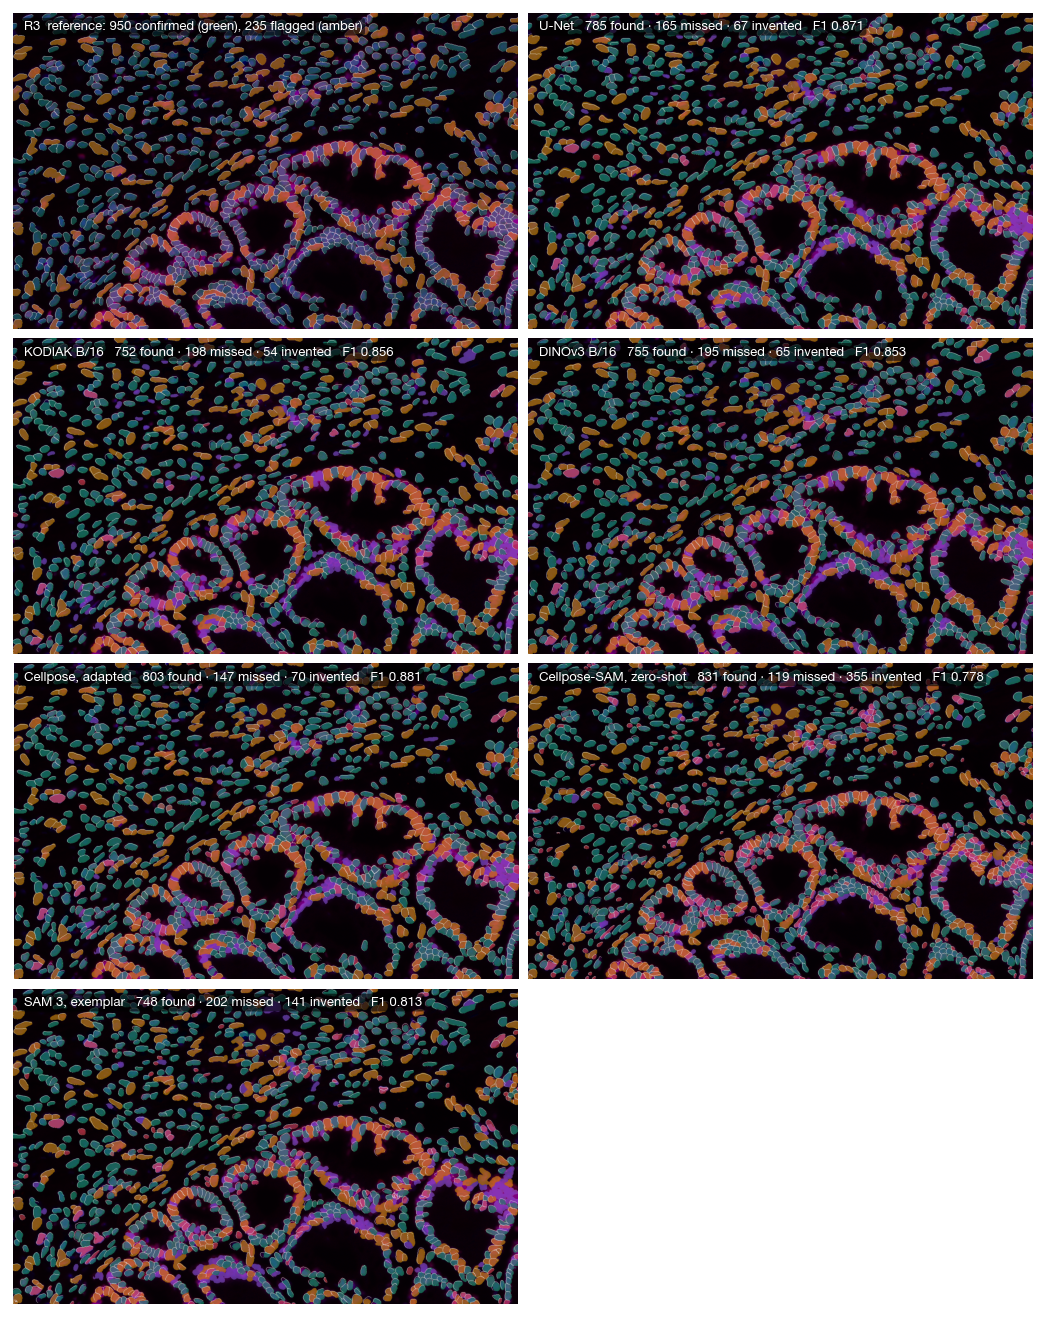

SLIDE-0236_R03: 1489 x 932 px = 484 x 303 µm | green found (true shape), violet missed, red invented (predicted shape), amber flagged; white = predicted outlines | seed 0


In [6]:
import cv2
REG = REGION_MAP or M.mean(axis=0).idxmin()                                     # the hardest region unless chosen
show = [m for m in SHOW if m in METHODS] or METHODS[:5]
stats = NormStats.load(DATASET / TEST_SLIDE / "stats.json")
NORMS = {m: (stats.lo[m], stats.hi[m]) for m in ("DAPI", "LAP2")}

def rgb_of(image):
    x = render_channels(image, ["DAPI", "LAP2"], NORMS, ("LAP2", None, "DAPI")).transpose(1, 2, 0)
    return np.clip(x * 1.6, 0, 1) ** 0.8

def contours_of(labels):
    """The pixel outlines of every instance (fast: a label differs from its 4-neighbours)."""
    e = np.zeros(labels.shape, bool)
    e[:, 1:] |= labels[:, 1:] != labels[:, :-1]; e[1:, :] |= labels[1:, :] != labels[:-1, :]
    return e & (labels > 0)

def paint(rgb, labels, status_of_id, colors, dim=0.5, alpha=0.6, outline=None):
    """Instances painted by class over a dimmed image; ``status_of_id[id]`` -> class name (ids start at 1)."""
    out = rgb * dim
    for cls, col in colors.items():
        ids = np.nonzero(status_of_id == cls)[0]; ids = ids[ids > 0]
        if ids.size:
            sel = np.isin(labels, ids); out[sel] = (1 - alpha) * out[sel] + alpha * hexrgb(col)
    if outline is not None:
        out[contours_of(outline)] = 0.9
    return out

def reference_rgb(rgb, labels, ignore):
    """The reference the way the verdict panels are drawn: dimmed image, confirmed cells filled green, flagged cells amber, white contours."""
    out = rgb * 0.55
    conf, wrong = (labels > 0) & ~ignore, (labels > 0) & ignore
    out[conf] = 0.6 * out[conf] + 0.4 * hexrgb(VERDICT["tp"]); out[wrong] = 0.5 * out[wrong] + 0.5 * hexrgb(VERDICT["wrong"])
    out[contours_of(labels)] = 0.92
    return out

image, labels, ignore = GT[REG]
rgb = rgb_of(image)
H, W = labels.shape
n = 1 + len(show); ncol = 2; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(7.6, 7.6 / ncol * H / W * nrow + 0.2), squeeze=False)
fig.subplots_adjust(wspace=0.02, hspace=0.03, left=0.003, right=0.997, top=0.99, bottom=0.005)
ax = axes[0, 0]
conf = np.where(ignore, 0, labels); wrong = np.where(ignore, labels, 0)
ref = reference_rgb(rgb, labels, ignore)
ax.imshow(ref); ax.set_axis_off(); chip(ax, f"R{regions[REG].region_id}  reference: {len(np.unique(conf)) - 1} confirmed (green), {len(np.unique(wrong)) - 1} flagged (amber)")
for j, m in enumerate(show, start=1):
    ax = axes[j // ncol, j % ncol]
    o = OUT[(m, REG)]
    if o is None:
        ax.set_axis_off(); continue
    gt_v = np.array([{"tp": "tp", "fn": "fn", "wrong": "wrong"}.get(x, "") for x in o["gt_status"]], dtype=object)
    img = paint(rgb, o["gt"], gt_v, {"tp": VERDICT["tp"], "fn": VERDICT["fn"], "wrong": VERDICT["wrong"]}, alpha=0.55)
    fp_ids = np.nonzero(o["pred_status"] == "fp")[0]; sel = np.isin(o["pred"], fp_ids[fp_ids > 0])
    img[sel] = 0.45 * img[sel] + 0.55 * hexrgb(VERDICT["fp"]); img[contours_of(o["pred"])] = 0.9
    ax.imshow(img); ax.set_axis_off()
    chip(ax, f"{lab(m)}   {o['tp']} found · {o['fn']} missed · {o['fp']} invented   F1 {2 * o['tp'] / max(2 * o['tp'] + o['fp'] + o['fn'], 1):.3f}")
for j in range(n, nrow * ncol):
    axes[j // ncol, j % ncol].set_axis_off()
plt.show()
print(f"{REG}: {W} x {H} px = {W * PX:.0f} x {H * PX:.0f} µm | green found (true shape), violet missed, red invented (predicted shape), amber flagged; white = predicted outlines | seed {SEED}")

**Figure 4 — Error maps of a whole region.** The hardest region of Slide 2 (or `REGION_MAP`): the reference with confirmed
cells outlined in green and flagged cells in amber, then each method's verdict at IoU 0.5 over the whole field of view —
found cells in green, missed in violet, invented in red, every prediction outlined. This is the view a segmentation
paper shows next to its table: whether the misses cluster in one kind of tissue (dense epithelium, a dim area, an edge)
or scatter, and whether two methods with the same F1 fail in the same places.

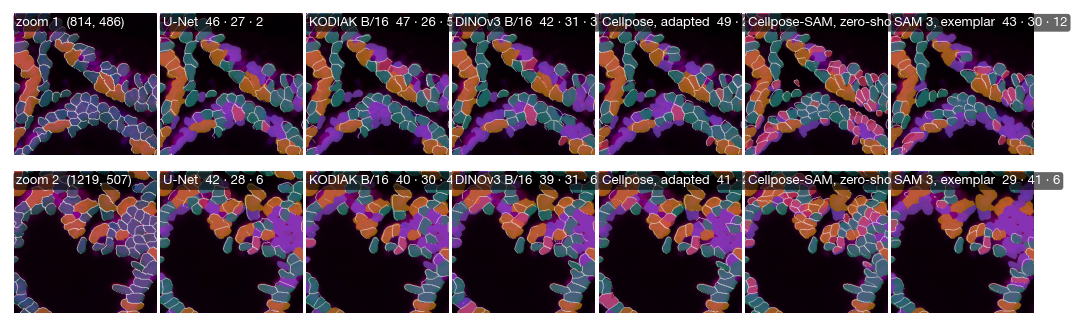

zooms: 256 px = 83 µm, the error hot spots of R3 (chips: found · missed · invented)


In [7]:
# the two 256-px windows of this region where the shown methods make the most errors (missed + invented pixels), pooled
Z = 256
heat = np.zeros(labels.shape, np.float32)
for m in show:
    o = OUT[(m, REG)]
    if o is None:
        continue
    heat += np.isin(o["gt"], np.nonzero(o["gt_status"] == "fn")[0]) + np.isin(o["pred"], np.nonzero(o["pred_status"] == "fp")[0])
box = cv2.boxFilter(heat, -1, (Z, Z), normalize=False, borderType=cv2.BORDER_CONSTANT)
ZOOMS = []
for _ in range(2):
    cy, cx = np.unravel_index(int(box.argmax()), box.shape)
    y0, x0 = int(np.clip(cy - Z // 2, 0, H - Z)), int(np.clip(cx - Z // 2, 0, W - Z)); ZOOMS.append((y0, x0))
    box[max(0, cy - Z):cy + Z, max(0, cx - Z):cx + Z] = 0                        # no overlap with the next pick
fig, axes = plt.subplots(len(ZOOMS), n, figsize=(7.6, 7.6 / n * len(ZOOMS) + 0.25), squeeze=False)
fig.subplots_adjust(wspace=0.03, hspace=0.05, left=0.003, right=0.997, top=0.95, bottom=0.005)
for i, (y0, x0) in enumerate(ZOOMS):
    sl = (slice(y0, y0 + Z), slice(x0, x0 + Z))
    ax = axes[i, 0]; ax.imshow(ref[sl]); ax.set_axis_off(); chip(ax, f"zoom {i + 1}  ({x0}, {y0})")
    for j, m in enumerate(show, start=1):
        ax = axes[i, j]; o = OUT[(m, REG)]
        if o is None:
            ax.set_axis_off(); continue
        gt_v = np.array([{"tp": "tp", "fn": "fn", "wrong": "wrong"}.get(x, "") for x in o["gt_status"]], dtype=object)
        img = paint(rgb[sl], o["gt"][sl], gt_v, {"tp": VERDICT["tp"], "fn": VERDICT["fn"], "wrong": VERDICT["wrong"]}, alpha=0.55)
        fp_ids = np.nonzero(o["pred_status"] == "fp")[0]; sel = np.isin(o["pred"][sl], fp_ids[fp_ids > 0])
        img[sel] = 0.45 * img[sel] + 0.55 * hexrgb(VERDICT["fp"]); img[contours_of(o["pred"][sl])] = 0.9
        ids_g = np.unique(o["gt"][sl]); ids_g = ids_g[ids_g > 0]; ids_p = np.unique(o["pred"][sl]); ids_p = ids_p[ids_p > 0]
        ax.imshow(img); ax.set_axis_off()
        chip(ax, f"{lab(m)}  {int((o['gt_status'][ids_g] == 'tp').sum())} · {int((o['gt_status'][ids_g] == 'fn').sum())} · {int((o['pred_status'][ids_p] == 'fp').sum())}")
for i, (y0, x0) in enumerate(ZOOMS):
    pass
plt.show()
print(f"zooms: {Z} px = {Z * PX:.0f} µm, the error hot spots of R{regions[REG].region_id} (chips: found · missed · invented)")

**Figure 4b — The error hot spots of the region, zoomed.** The two 256 px windows where the shown methods together miss
and invent the most, through every method: the place to see *why* a cell is lost — a dim nucleus, two nuclei that touch,
a large cell cut in two — and whether the methods lose the same cells or different ones.

## 6. Where the errors are

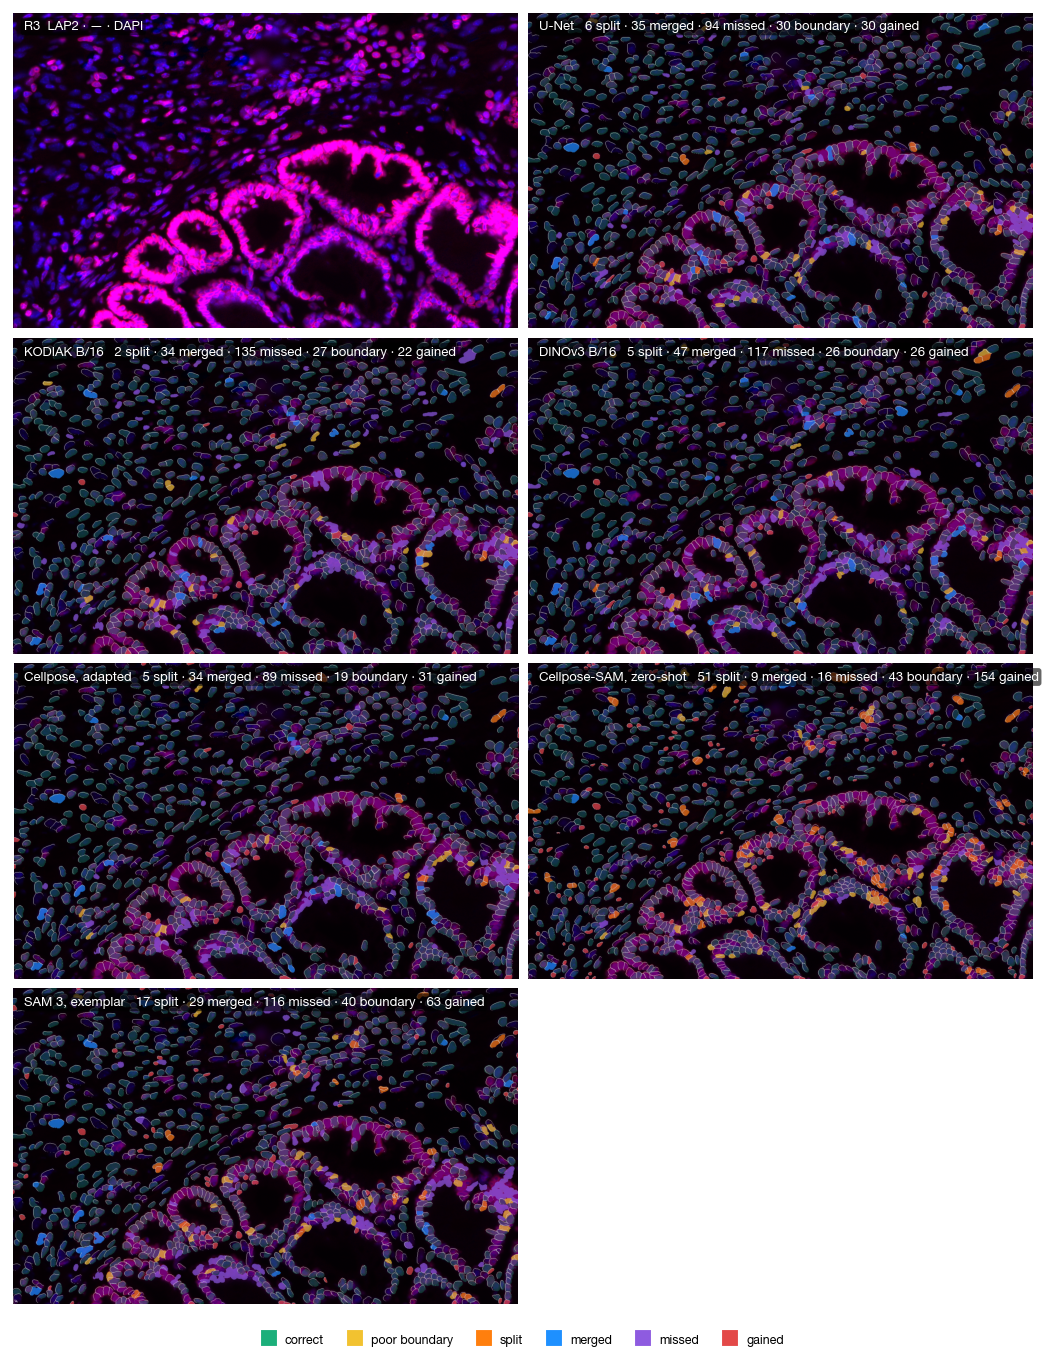

In [8]:
fig, axes = plt.subplots(nrow, ncol, figsize=(7.6, 7.6 / ncol * H / W * nrow + 0.2), squeeze=False)
fig.subplots_adjust(wspace=0.02, hspace=0.03, left=0.003, right=0.997, top=0.99, bottom=0.005)
ax = axes[0, 0]
ax.imshow(rgb); ax.set_axis_off(); chip(ax, f"R{regions[REG].region_id}  LAP2 · — · DAPI")
for j, m in enumerate(show, start=1):
    ax = axes[j // ncol, j % ncol]
    o = OUT[(m, REG)]
    if o is None:
        ax.set_axis_off(); continue
    g_cls = np.concatenate([[""], o["g_cls"]]); p_cls = np.concatenate([[""], o["p_cls"]])
    img = paint(rgb, o["gt"], g_cls, {c_: TAXO[c_] for c_ in ("boundary", "split", "merged", "missed")}, dim=0.45, alpha=0.7)
    ok = np.isin(o["gt"], np.nonzero(g_cls == "correct")[0]); img[ok] = 0.7 * img[ok] + 0.3 * hexrgb(TAXO["correct"])
    gained = np.isin(o["pred"], np.nonzero(p_cls == "gained")[0]); img[gained] = 0.3 * img[gained] + 0.7 * hexrgb(TAXO["gained"])
    img[contours_of(o["pred"])] = 0.85
    ax.imshow(img); ax.set_axis_off()
    counts = {c_: int((o["g_cls"] == c_).sum()) for c_ in ("split", "merged", "missed", "boundary")}; counts["gained"] = int((o["p_cls"] == "gained").sum())
    chip(ax, f"{lab(m)}   " + " · ".join(f"{v} {c_}" for c_, v in counts.items()))
for j in range(n, nrow * ncol):
    axes[j // ncol, j % ncol].set_axis_off()
fig.legend(handles=[plt.Line2D([], [], marker="s", ms=7, ls="", color=TAXO[c_], label=TAXO_LABEL[c_].split(" (")[0]) for c_ in TAXO], ncol=6,
           loc="lower center", bbox_to_anchor=(0.5, -0.035), fontsize=6.6, handlelength=1.0)
plt.show()

**Figure 5 — Where the errors are.** The same region with the taxonomy of Figure 3c painted on it: split cells orange,
merged cells blue, missed cells violet, poor boundaries yellow, gained objects red, correct cells faint green, every
prediction outlined. Merges sit where nuclei touch — packed epithelium — and splits on large or elongated cells; the
missed cells are the dim and the small ones. Two methods with equal F1 can have opposite maps here, and it is the
merges and splits, not the boundaries, that reach the phenotype and neighborhood analyses.

## 7. The same crops through every method

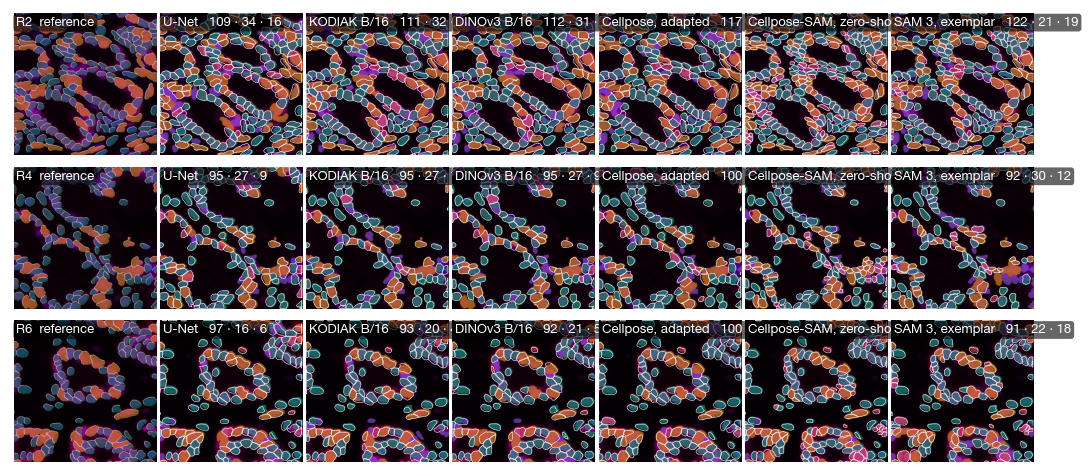

chips: found · missed · invented at IoU 0.5 | seed 0 of each trained method | crop 384 px = 125 µm | green found, violet missed, red invented, amber = flagged (never scored); white = predicted outlines


In [9]:
stats = NormStats.load(DATASET / TEST_SLIDE / "stats.json")
NORMS = {m: (stats.lo[m], stats.hi[m]) for m in ("DAPI", "LAP2")}
show = [m for m in SHOW if m in METHODS] or METHODS[:5]

def rgb_of(image):
    x = render_channels(image, ["DAPI", "LAP2"], NORMS, ("LAP2", None, "DAPI")).transpose(1, 2, 0)
    return np.clip(x * 1.6, 0, 1) ** 0.8

def outlines(ax, labels, color, lw=0.5, alpha=0.95):
    import cv2
    segs = []
    for cid in np.unique(labels)[1:]:
        cs, _ = cv2.findContours((labels == cid).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        segs += [c[:, 0, :] for c in cs if len(c) > 2]
    ax.add_collection(LineCollection([np.vstack([s_, s_[:1]]) for s_ in segs], colors=color, linewidths=lw, alpha=alpha))

def verdict_rgb(rgb, o):
    """TP green (true shape), FN violet (true shape), FP red (predicted shape), the flagged cells amber, over a dimmed image."""
    out = rgb * 0.55
    for verdict, labels, status in (("tp", o["gt"], o["gt_status"]), ("fn", o["gt"], o["gt_status"]), ("wrong", o["gt"], o["gt_status"]), ("fp", o["pred"], o["pred_status"])):
        ids = np.nonzero(status == verdict)[0]; ids = ids[ids > 0]
        if ids.size:
            sel = np.isin(labels, ids); out[sel] = 0.45 * out[sel] + 0.55 * hexrgb(VERDICT[verdict])
    return out

ncol = 1 + len(show)
fig, axes = plt.subplots(len(CROPS), ncol, figsize=(7.6, 7.6 / ncol * len(CROPS) + 0.3), squeeze=False)
fig.subplots_adjust(wspace=0.03, hspace=0.05, left=0.003, right=0.997, top=0.95, bottom=0.005)
for i, (k, y0, x0) in enumerate(CROPS):
    image, labels, ignore = GT[k]
    sl = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))
    rgb = rgb_of(image[:, sl[0], sl[1]])
    ax = axes[i, 0]
    ax.imshow(reference_rgb(rgb, labels[sl], ignore[sl]))
    chip(ax, f"R{regions[k].region_id}  reference"); ax.set_axis_off()
    for j, m in enumerate(show):
        ax = axes[i, j + 1]
        o = OUT[(m, k)]
        if o is None:
            ax.set_axis_off(); ax.text(0.5, 0.5, "not evaluated", ha="center", va="center", fontsize=7, color=MUTED, transform=ax.transAxes); continue
        oc = {"gt": o["gt"][sl], "pred": o["pred"][sl], "gt_status": o["gt_status"], "pred_status": o["pred_status"]}
        ax.imshow(verdict_rgb(rgb, oc)); outlines(ax, oc["pred"], "white", lw=0.35, alpha=0.8)
        tp = int(np.isin(oc["gt_status"][np.unique(oc["gt"])[1:]], ["tp"]).sum()); fn = int(np.isin(oc["gt_status"][np.unique(oc["gt"])[1:]], ["fn"]).sum())
        fp = int((oc["pred_status"][np.unique(oc["pred"])[1:]] == "fp").sum())
        chip(ax, f"{lab(m)}   {tp} · {fn} · {fp}"); ax.set_axis_off()
plt.show()
print(f"chips: found · missed · invented at IoU 0.5 | seed {SEED} of each trained method | crop {CROP} px = {CROP * PX:.0f} µm | "
      "green found, violet missed, red invented, amber = flagged (never scored); white = predicted outlines")

**Figure 7 — The same crops through every method.** Left: the reference over the dimmed segmenter view (LAP2 red, DAPI
blue), confirmed cells filled green, flagged cells amber, every cell outlined. Then one column per method: the verdict at IoU 0.5 — found cells in green
with their true shape, missed cells in violet, invented objects in red with their predicted shape, every prediction
outlined in white — and in the corner the counts found · missed · invented. Read across a row for what the methods disagree on; read down a column
for what one method does in different tissue. Edit `CROPS` and `SHOW` to look elsewhere.

## 8. Consensus, stability, and HALO's own errors

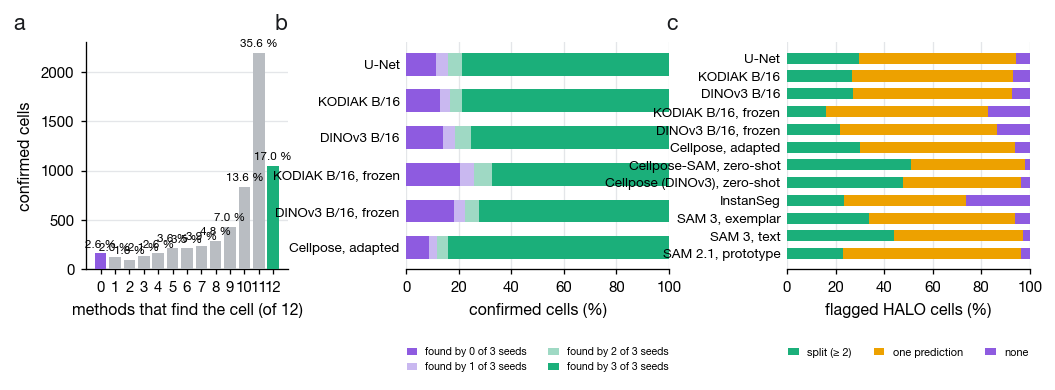

6,152 confirmed cells | found by every method: 17.0 % | by none: 162 (2.6 %) -> the ceiling any method can reach on this reference is about 97.4 % recall
flagged HALO cells split into ≥ 2 objects: U-Net 30 %, KODIAK B/16 27 %, DINOv3 B/16 27 %, KODIAK B/16, frozen 16 %, DINOv3 B/16, frozen 22 %, Cellpose, adapted 30 %, Cellpose-SAM, zero-shot 51 %, Cellpose (DINOv3), zero-shot 48 %, InstanSeg 24 %, SAM 3, exemplar 34 %, SAM 3, text 44 %, SAM 2.1, prototype 23 %


In [10]:
from scipy import ndimage as ndi
def outcomes_run(run, k):
    path = PRED / run / f"{k}.npz"
    return instance_outcomes(GT[k][1], load_prediction(path), ignore=GT[k][2], thr=0.5) if path.is_file() else None
OUT_SEEDS = {(r["run"], k): outcomes_run(r["run"], k) for m in METHODS for r in BY[m] for k in KEYS}   # every seed of every method
TRAINED = [m for m in METHODS if any(r["seed"] is not None for r in BY[m])]

# (a) consensus: how many methods (their chosen seed) find each confirmed cell
found_by, per_cell = [], []
for k in KEYS:
    os_ = [OUT[(m, k)] for m in METHODS if OUT[(m, k)] is not None]
    if not os_:
        continue
    scored = np.isin(os_[0]["gt_status"][1:], ["tp", "fn"])
    hits = np.sum([(o["gt_status"][1:] == "tp") for o in os_], axis=0)
    found_by.append(hits[scored]); per_cell.append(pd.DataFrame({"key": k, "gid": np.nonzero(scored)[0] + 1, "hits": hits[scored]}))
found_by = np.concatenate(found_by); per_cell = pd.concat(per_cell)
n_methods = len([m for m in METHODS if OUT[(m, KEYS[0])] is not None])
# (b) stability: for each trained method, how many of its seeds find each confirmed cell
stab = {}
for m in TRAINED:
    runs_m = [r["run"] for r in BY[m]]
    hits = []
    for k in KEYS:
        os_ = [OUT_SEEDS[(run, k)] for run in runs_m if OUT_SEEDS[(run, k)] is not None]
        if not os_:
            continue
        scored = np.isin(os_[0]["gt_status"][1:], ["tp", "fn"])
        hits.append(np.sum([(o["gt_status"][1:] == "tp") for o in os_], axis=0)[scored])
    h = np.concatenate(hits); n_s = len(runs_m)
    stab[m] = np.array([(h == j).mean() for j in range(n_s + 1)])
# (c) HALO's merges: for every flagged cell, how many predictions cover at least a fifth of it
fix = {}
for m in METHODS:
    counts = {"split (≥ 2)": 0, "one prediction": 0, "none": 0}
    for k in KEYS:
        o = OUT[(m, k)]
        if o is None or not len(o["area_g"]):
            continue
        wrong_ids = np.nonzero(o["gt_status"][1:] == "wrong")[0]
        for g in wrong_ids:
            n_ = int((o["cover_g"][g] >= 0.2).sum())
            counts["split (≥ 2)" if n_ >= 2 else "one prediction" if n_ == 1 else "none"] += 1
    fix[m] = counts
fig = plt.figure(figsize=(7.6, 2.9))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.3, 1.2], wspace=0.5, left=0.07, right=0.99, top=0.88, bottom=0.3)
a = fig.add_subplot(gs[0])
ks = np.arange(n_methods + 1); cnt = np.array([(found_by == j).sum() for j in ks])
a.bar(ks, cnt, color=["#8E5BE0"] + ["#B9BDC2"] * (n_methods - 1) + ["#1BAF7A"], zorder=3)
for j, v in zip(ks, cnt):
    a.text(j, v + len(found_by) * 0.01, f"{100 * v / len(found_by):.1f} %", ha="center", fontsize=6.2)
a.set_xticks(ks); a.set_xlabel(f"methods that find the cell (of {n_methods})"); a.set_ylabel("confirmed cells"); ygrid(a)
panel(a, "a", dx=-0.3)
b_ = fig.add_subplot(gs[1])
y = np.arange(len(TRAINED))[::-1]
shades = ["#8E5BE0", "#C9B8F0", "#9FD9C4", "#1BAF7A"]
for i, m in enumerate(TRAINED):
    left = 0
    for j, frac in enumerate(stab[m]):
        col = shades[min(j, 3)] if len(stab[m]) == 4 else plt.cm.PRGn(0.15 + 0.7 * j / max(len(stab[m]) - 1, 1))
        b_.barh(y[i], 100 * frac, left=left, color=col, height=0.62, zorder=3, label=(f"found by {j} of {len(stab[m]) - 1} seeds" if i == 0 else None))
        left += 100 * frac
b_.set_yticks(y, [lab(m) for m in TRAINED], fontsize=7.2); b_.set_xlim(0, 100); b_.set_xlabel("confirmed cells (%)")
b_.legend(fontsize=5.6, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, handlelength=1.0); xgrid(b_); b_.spines["left"].set_visible(False); b_.tick_params(axis="y", length=0)
panel(b_, "b", dx=-0.45)
c_ = fig.add_subplot(gs[2])
y2 = np.arange(len(METHODS))[::-1]
for i, m in enumerate(METHODS):
    tot_ = max(sum(fix[m].values()), 1); left = 0
    for cls, col in (("split (≥ 2)", "#1BAF7A"), ("one prediction", "#EDA100"), ("none", "#8E5BE0")):
        v = 100 * fix[m][cls] / tot_
        c_.barh(y2[i], v, left=left, color=col, height=0.62, zorder=3, label=cls if i == 0 else None); left += v
c_.set_yticks(y2, [lab(m) for m in METHODS], fontsize=7.2); c_.set_xlim(0, 100); c_.set_xlabel("flagged HALO cells (%)")
c_.legend(fontsize=5.8, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, handlelength=1.0); xgrid(c_); c_.spines["left"].set_visible(False); c_.tick_params(axis="y", length=0)
panel(c_, "c", dx=-0.45)
plt.show()
never = per_cell[per_cell.hits == 0]
print(f"{len(found_by):,} confirmed cells | found by every method: {100 * (found_by == n_methods).mean():.1f} % | by none: {len(never):,} ({100 * len(never) / len(found_by):.1f} %) "
      f"-> the ceiling any method can reach on this reference is about {100 * (1 - len(never) / len(found_by)):.1f} % recall")
print("flagged HALO cells split into ≥ 2 objects: " + ", ".join(f"{lab(m)} {100 * fix[m]['split (≥ 2)'] / max(sum(fix[m].values()), 1):.0f} %" for m in METHODS))

**Figure 8 — What is a model error, and what is not.** (a) Consensus: for every confirmed cell, how many methods find it.
The cells found by none are as likely to be reference cells that no segmenter can produce from DAPI + LAP2 — a dim or
out-of-focus nucleus, a cell the reviewer confirmed but that is not separable in these two channels — as model failures;
their share bounds the recall any method can reach, and the methods differ only within the cells in between. (b)
Test–retest: for each trained method, whether a cell is found by all of its seeds, some, or none. A method whose seeds
disagree on many cells feeds an unstable substrate to the downstream analyses even at the same mean F1. (c) The cells the
expert flagged are, in the reviewed regions, HALO's merges. A model that covers such a cell with two or more objects has
separated what the commercial tool fused — evidence that the models are not merely reproducing the reference's
errors.

## 9. Where the misses come from, and which differences are real

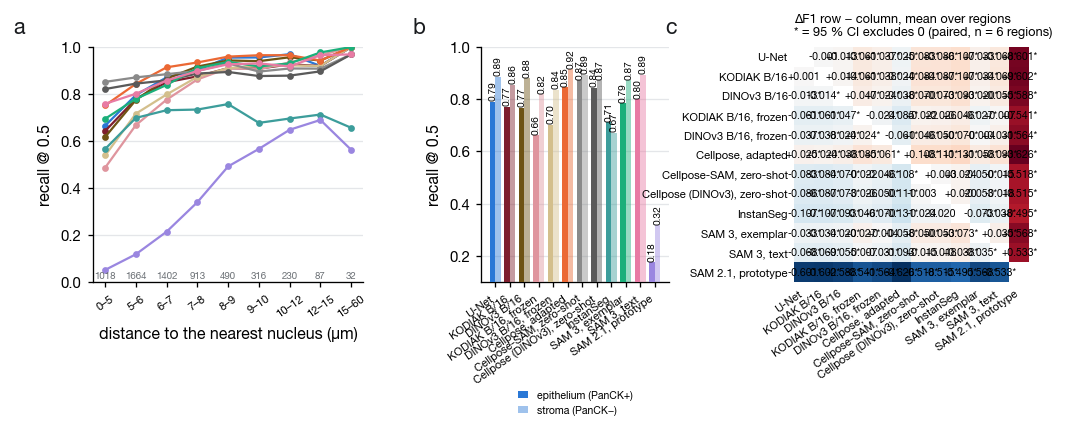

PanCK compartment threshold (Otsu on log10 cell means): 200 counts | U-Net: epithelium 0.790, stroma 0.886 | KODIAK B/16: epithelium 0.772, stroma 0.855 | DINOv3 B/16: epithelium 0.768, stroma 0.880 | KODIAK B/16, frozen: epithelium 0.663, stroma 0.818 | DINOv3 B/16, frozen: epithelium 0.701, stroma 0.835 | Cellpose, adapted: epithelium 0.846, stroma 0.915 | Cellpose-SAM, zero-shot: epithelium 0.873, stroma 0.894 | Cellpose (DINOv3), zero-shot: epithelium 0.844, stroma 0.873 | InstanSeg: epithelium 0.712, stroma 0.672 | SAM 3, exemplar: epithelium 0.785, stroma 0.872 | SAM 3, text: epithelium 0.800, stroma 0.893 | SAM 2.1, prototype: epithelium 0.176, stroma 0.316


In [11]:
from scipy.spatial import cKDTree
from scipy import stats as sps
from skimage.filters import threshold_otsu
# per confirmed cell: nearest-neighbour distance (crowding) and PanCK mean (compartment), from one seed per method
rows_c = []
panck_all = {}
for k in KEYS:
    o0 = OUT[(METHODS[0], k)]
    if o0 is None:
        continue
    gt = o0["gt"]; ids = np.arange(1, int(gt.max()) + 1)
    cen = np.array(ndi.center_of_mass(np.ones_like(gt), labels=gt, index=ids))
    d, _ = cKDTree(cen).query(cen, k=2); nn = d[:, 1] * PX
    panck = mx.read_region(regions[k].box, ["PanCK"], 0)[0].astype(np.float32)
    pm = np.asarray(ndi.mean(panck, labels=gt, index=ids)); panck_all[k] = pm
    for m in METHODS:
        o = OUT[(m, k)]
        if o is None:
            continue
        st = o["gt_status"][1:]
        sel = np.isin(st, ["tp", "fn"])
        rows_c.append(pd.DataFrame({"method": m, "key": k, "nn_um": nn[sel], "panck": pm[sel], "found": st[sel] == "tp"}))
cells = pd.concat(rows_c)
thr_p = threshold_otsu(np.log10(np.concatenate(list(panck_all.values())) + 1))
cells["compartment"] = np.where(np.log10(cells.panck + 1) >= thr_p, "epithelium (PanCK+)", "stroma (PanCK−)")
nn_bins = np.array([0, 5, 6, 7, 8, 9, 10, 12, 15, 60])
cells["nn_bin"] = pd.cut(cells.nn_um, nn_bins, right=False)
# paired per-region differences between methods, mean over seeds per region
pr = per.groupby(["method", "key"]).f1.mean().unstack().reindex(index=METHODS)
D = np.full((len(METHODS), len(METHODS)), np.nan); CI = np.full_like(D, np.nan)
for i, a_ in enumerate(METHODS):
    for j, b2 in enumerate(METHODS):
        if i != j:
            d = (pr.loc[a_] - pr.loc[b2]).dropna().values
            D[i, j] = d.mean(); CI[i, j] = sps.t.ppf(0.975, len(d) - 1) * d.std(ddof=1) / np.sqrt(len(d)) if len(d) > 1 else np.nan
fig = plt.figure(figsize=(7.6, 3.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1.3, 0.9, 1.2], wspace=0.5, left=0.07, right=0.99, top=0.88, bottom=0.3)
a = fig.add_subplot(gs[0])
for m in METHODS:
    g = cells[cells.method == m].groupby("nn_bin", observed=False).found.mean()
    a.plot(np.arange(len(g)), g.values, "-o", ms=2.6, lw=1.2, color=MCOLOR.get(m, "#999"), label=lab(m))
n_nn = cells[cells.method == METHODS[0]].groupby("nn_bin", observed=False).size()
for i, n in enumerate(n_nn.values):
    a.text(i, a.get_ylim()[0] + 0.01, f"{n}", ha="center", fontsize=5.2, color=MUTED)
a.set_xticks(np.arange(len(nn_bins) - 1), [f"{nn_bins[i]:g}–{nn_bins[i + 1]:g}" for i in range(len(nn_bins) - 1)], fontsize=6, rotation=35)
a.set_xlabel("distance to the nearest nucleus (µm)"); a.set_ylabel("recall @ 0.5"); ygrid(a)
a.set_ylim(np.floor((cells.groupby(["method", "nn_bin"], observed=False).found.mean().min() - 0.05) * 10) / 10, 1.0)
panel(a, "a", dx=-0.25)
b_ = fig.add_subplot(gs[1])
comp = cells.groupby(["method", "compartment"]).found.mean().unstack().reindex(index=METHODS)
x = np.arange(len(METHODS)); wdt = 0.38
b_.bar(x - wdt / 2, comp.iloc[:, 0], wdt, color=[MCOLOR.get(m, "#999") for m in METHODS], zorder=3, label=comp.columns[0])
b_.bar(x + wdt / 2, comp.iloc[:, 1], wdt, color=[MCOLOR.get(m, "#999") for m in METHODS], alpha=0.45, zorder=3, label=comp.columns[1])
for xi, (v1, v2) in zip(x, comp.values):
    b_.text(xi - wdt / 2, v1 + 0.004, f"{v1:.2f}", ha="center", fontsize=5.4, rotation=90, va="bottom"); b_.text(xi + wdt / 2, v2 + 0.004, f"{v2:.2f}", ha="center", fontsize=5.4, rotation=90, va="bottom")
b_.set_xticks(x, [lab(m) for m in METHODS], fontsize=6, rotation=35, ha="right"); b_.set_ylabel("recall @ 0.5"); ygrid(b_)
b_.set_ylim(np.floor((comp.values.min() - 0.05) * 10) / 10, 1.0)
b_.legend(fontsize=5.6, loc="upper center", bbox_to_anchor=(0.5, -0.42), ncol=1, handlelength=1.0)
panel(b_, "b", dx=-0.3)
c_ = fig.add_subplot(gs[2])
vmax = np.nanmax(np.abs(D)) if np.isfinite(D).any() else 0.01
c_.imshow(D, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
for i in range(len(METHODS)):
    for j in range(len(METHODS)):
        if i != j and np.isfinite(D[i, j]):
            sig = abs(D[i, j]) > CI[i, j] if np.isfinite(CI[i, j]) else False
            c_.text(j, i, f"{D[i, j]:+.3f}" + ("*" if sig else ""), ha="center", va="center", fontsize=5.6, fontweight="bold" if sig else "normal")
c_.set_xticks(range(len(METHODS)), [lab(m) for m in METHODS], fontsize=6, rotation=35, ha="right"); c_.set_yticks(range(len(METHODS)), [lab(m) for m in METHODS], fontsize=6)
c_.set_title("ΔF1 row − column, mean over regions\n* = 95 % CI excludes 0 (paired, n = 6 regions)", fontsize=6.8); c_.tick_params(length=0)
for sp_ in c_.spines.values(): sp_.set_visible(False)
panel(c_, "c", dx=-0.5)
plt.show()
print(f"PanCK compartment threshold (Otsu on log10 cell means): {10 ** thr_p - 1:.0f} counts | " + " | ".join(f"{lab(m)}: epithelium {comp.loc[m].iloc[0]:.3f}, stroma {comp.loc[m].iloc[1]:.3f}" for m in METHODS))

**Figure 9 — Where the misses come from, and which differences are real.** (a) Recall against the distance to the nearest
nucleus, cells per bin along the bottom: recall collapses below about 7 µm — two nuclei closer than a nuclear diameter —
and is near perfect for isolated cells, for every method. The misses are a crowding effect, not a detection failure.
(b) Recall in the epithelium (PanCK-positive by an Otsu gate on the cell's PanCK mean) against the stroma: the same
effect by tissue compartment, which is what the phenotype and niche analyses will inherit. (c) Every pair of methods
compared region by region, mean ΔF1 over the six regions of Slide 2 with a paired 95 % confidence interval — differences
without a star are within what the regions themselves vary by, whatever the seed means say.